<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/5_gravity_cosmo_strings/general_relativity/gr_ch02_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*General Relativity* — `gr_ch02_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# GR Ch2 Figures — Introducing Differential Geometry
Dark-theme figures for Quarto Reveal.js slides.  
Run all cells, then download the `figures/` folder.

**Figures:**
1. `gr_ch2_fig01_manifold_patches.png` — manifold with local patches
2. `gr_ch2_fig02_charts.png` — two overlapping charts on M
3. `gr_ch2_fig03_sphere_charts.png` — two charts on S²
4. `gr_ch2_fig04_tangent_space.png` — tangent plane at a point
5. `gr_ch2_fig05_integral_curves.png` — flow lines on S² and ℝ²

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch, Ellipse
from mpl_toolkits.mplot3d import Axes3D
import os

os.makedirs('figures', exist_ok=True)

# Colour palette (matching gr_slides.css)
BG     = '#0d1117'
GOLD   = '#d4a017'
BLUE   = '#388bfd'
GREEN  = '#3fb950'
RED    = '#f85149'
PURPLE = '#bc8cff'
MUTED  = '#8b949e'
TEXT   = '#e6edf3'

plt.rcParams.update({
    'figure.facecolor': BG,
    'axes.facecolor':   BG,
    'text.color':       TEXT,
    'axes.labelcolor':  TEXT,
    'xtick.color':      MUTED,
    'ytick.color':      MUTED,
    'axes.edgecolor':   MUTED,
    'grid.color':       '#21262d',
    'font.family':      'DejaVu Sans',
    'mathtext.fontset': 'dejavusans',
})
print('Setup done.')

Setup done.


## Fig 1: Manifold with Local Patches

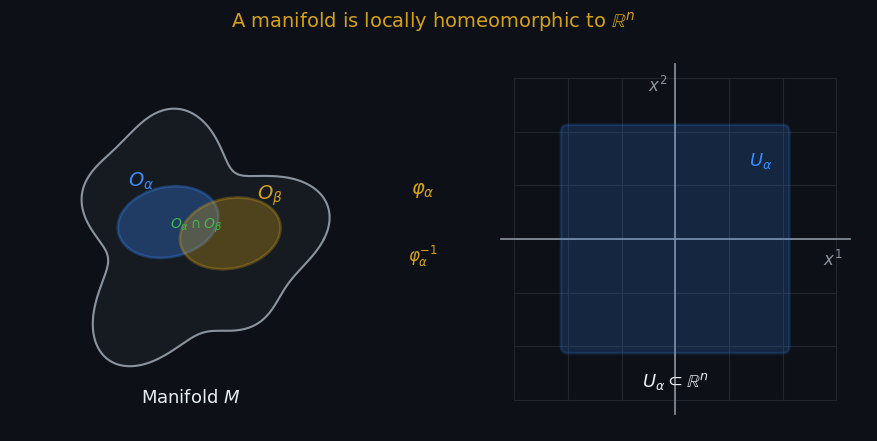

Fig 1 saved.


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), facecolor=BG)
fig.patch.set_facecolor(BG)

# Left: curved surface (wavy 2D)
ax = axes[0]
ax.set_facecolor(BG)
ax.set_aspect('equal')
ax.axis('off')

# Draw a blob representing the manifold
theta = np.linspace(0, 2*np.pi, 300)
r = 1.0 + 0.18*np.cos(3*theta) + 0.12*np.sin(5*theta)
x_blob = r * np.cos(theta)
y_blob = r * np.sin(theta)
ax.fill(x_blob, y_blob, color='#161b22', zorder=1)
ax.plot(x_blob, y_blob, color=MUTED, lw=1.5, zorder=2)

# # Draw two overlapping patches
# for cx, cy, col, label in [(-0.3, 0.2, BLUE, r'$O_\alpha$'), (0.35, -0.15, GOLD, r'$O_\beta$')]:
#     patch = Ellipse((cx, cy), 0.8, 0.6, angle=15,
#                     fill=True, facecolor=col, alpha=0.25,
#                     edgecolor=col, linewidth=2, zorder=3)
#     ax.add_patch(patch)
#     ax.text(cx, cy+0.4, label, color=col, fontsize=14, ha='center', fontweight='bold', zorder=5)

# # Overlap label
# ax.text(0.05, 0.05, r'$O_\alpha\cap O_\beta$', color=GREEN, fontsize=11, ha='center', zorder=5)

# Draw two overlapping patches — partially overlapping
for cx, cy, col, label, label_offset in [
    (-0.20, 0.15, BLUE, r'$O_\alpha$', (-0.24, 0.32)),
    ( 0.35, 0.05, GOLD, r'$O_\beta$',  ( 0.35, 0.30)),
]:
    patch = Ellipse((cx, cy), 0.90, 0.62, angle=12,
                    fill=True, facecolor=col, alpha=0.30,
                    edgecolor=col, linewidth=2, zorder=3)
    ax.add_patch(patch)
    ax.text(cx + label_offset[0], cy + label_offset[1],
            label, color=col, fontsize=14, ha='center',
            fontweight='bold', zorder=6)

ax.text(0.05, 0.10, r'$O_\alpha\cap O_\beta$',
        color=GREEN, fontsize=10, ha='center', zorder=6)

ax.text(0, -1.45, r'Manifold $M$', color=TEXT, fontsize=13, ha='center')
ax.set_xlim(-1.6, 1.6)
ax.set_ylim(-1.7, 1.7)

# Right: local patch looks like R^n
ax2 = axes[1]
ax2.set_facecolor(BG)
ax2.set_aspect('equal')
ax2.axis('off')

# Draw a grid representing R^2
for xi in np.linspace(-1.2, 1.2, 7):
    ax2.plot([xi, xi], [-1.2, 1.2], color='#21262d', lw=0.8, zorder=1)
    ax2.plot([-1.2, 1.2], [xi, xi], color='#21262d', lw=0.8, zorder=1)

ax2.plot([-1.3, 1.3], [0, 0], color=MUTED, lw=1.2, zorder=2)
ax2.plot([0, 0], [-1.3, 1.3], color=MUTED, lw=1.2, zorder=2)
ax2.text(1.1, -0.2, r'$x^1$', color=MUTED, fontsize=12)
ax2.text(-0.2, 1.1, r'$x^2$', color=MUTED, fontsize=12)

# Highlight a patch U
rect = mpatches.FancyBboxPatch((-0.8, -0.8), 1.6, 1.6,
    boxstyle='round,pad=0.05', facecolor=BLUE, alpha=0.18,
    edgecolor=BLUE, linewidth=2, zorder=3)
ax2.add_patch(rect)
ax2.text(0, -1.1, r'$U_\alpha \subset \mathbb{R}^n$', color=TEXT, fontsize=13, ha='center')
ax2.text(0.55, 0.55, r'$U_\alpha$', color=BLUE, fontsize=13, fontweight='bold')

# Arrow between the two panels (homeomorphism)
fig.text(0.49, 0.56, r'$\varphi_\alpha$', color=GOLD, fontsize=14, ha='center')
fig.text(0.49, 0.41, r'$\varphi_\alpha^{-1}$', color=GOLD, fontsize=12, ha='center')

plt.tight_layout(rect=[0, 0, 1, 0.92])
fig.suptitle('A manifold is locally homeomorphic to $\\mathbb{R}^n$',
             color=GOLD, fontsize=14, y=0.97)
plt.savefig('figures/gr_ch2_fig01_manifold_patches.png', dpi=150, bbox_inches='tight',
            facecolor=BG)
plt.show()
print('Fig 1 saved.')

## Fig 2: Two Overlapping Charts on M

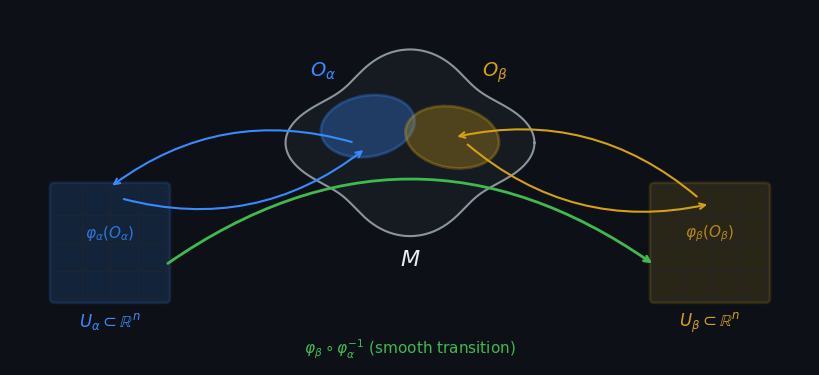

Fig 2 saved.


In [3]:
fig, ax = plt.subplots(figsize=(8, 6), facecolor=BG)
ax.set_facecolor(BG)

# 핵심: 비율 + 중심 고정
ax.set_aspect('equal', adjustable='box')
ax.set_anchor('C')
ax.axis('off')

# ---- Manifold M ----
theta = np.linspace(0, 2*np.pi, 300)
r_m = 1.0 + 0.12*np.cos(4*theta)

cx, cy = 0.0, 0.2   # 중심을 살짝 위로 (시각적 밸런스)
mx = cx + r_m * np.cos(theta)
my = cy + r_m * np.sin(theta) * 0.75

ax.fill(mx, my, color='#161b22', zorder=1)
ax.plot(mx, my, color=MUTED, lw=1.5, zorder=2)

ax.text(cx, cy-1.1, r'$M$', color=TEXT, fontsize=16,
        ha='center', fontweight='bold')

# ---- patches ----
eA = Ellipse((cx-0.38, cy+0.15), 0.85, 0.55, angle=10,
             facecolor=BLUE, alpha=0.3, edgecolor=BLUE, lw=2, zorder=3)
eB = Ellipse((cx+0.38, cy+0.05), 0.85, 0.55, angle=-10,
             facecolor=GOLD, alpha=0.3, edgecolor=GOLD, lw=2, zorder=3)

ax.add_patch(eA)
ax.add_patch(eB)

ax.text(cx-0.9, cy+0.6, r'$O_\alpha$', color=BLUE, fontsize=14, fontweight='bold')
ax.text(cx+0.65, cy+0.6, r'$O_\beta$', color=GOLD, fontsize=14, fontweight='bold')

# ---- Arrow 스타일 ----
base_arrow = dict(arrowstyle='->', lw=1.5,
                  connectionstyle='arc3,rad=0.25')

arrow_blue = dict(**base_arrow, color=BLUE)
arrow_gold = dict(**base_arrow, color=GOLD)

# ---- U_alpha ----
for xi in np.linspace(-3.2, -2.2, 5):
    ax.plot([xi, xi], [-1.2, -0.2], color='#21262d', lw=0.7)
for yi in np.linspace(-1.2, -0.2, 5):
    ax.plot([-3.2, -2.2], [yi, yi], color='#21262d', lw=0.7)

ax.add_patch(mpatches.FancyBboxPatch((-3.2, -1.2), 1.0, 1.0,
    boxstyle='round,pad=0.04', facecolor=BLUE, alpha=0.15,
    edgecolor=BLUE, lw=2))

ax.text(-2.7, -1.45, r'$U_\alpha \subset \mathbb{R}^n$',
        color=BLUE, fontsize=12, ha='center')
ax.text(-2.7, -0.65, r'$\varphi_\alpha(O_\alpha)$',
        color=BLUE, fontsize=11, ha='center', alpha=0.8)

# ---- U_beta ----
for xi in np.linspace(2.2, 3.2, 5):
    ax.plot([xi, xi], [-1.2, -0.2], color='#21262d', lw=0.7)
for yi in np.linspace(-1.2, -0.2, 5):
    ax.plot([2.2, 3.2], [yi, yi], color='#21262d', lw=0.7)

ax.add_patch(mpatches.FancyBboxPatch((2.2, -1.2), 1.0, 1.0,
    boxstyle='round,pad=0.04', facecolor=GOLD, alpha=0.15,
    edgecolor=GOLD, lw=2))

ax.text(2.7, -1.45, r'$U_\beta \subset \mathbb{R}^n$',
        color=GOLD, fontsize=12, ha='center')
ax.text(2.7, -0.65, r'$\varphi_\beta(O_\beta)$',
        color=GOLD, fontsize=11, ha='center', alpha=0.8)

# ---- arrows ----
ax.annotate('', xy=(-2.7, -0.2), xytext=(cx-0.5, cy),
            arrowprops=arrow_blue)
ax.annotate('', xy=(cx-0.4, cy-0.05), xytext=(-2.6, -0.3),
            arrowprops=arrow_blue)

ax.annotate('', xy=(2.7, -0.35), xytext=(cx+0.5, cy),
            arrowprops=arrow_gold)
ax.annotate('', xy=(cx+0.4, cy+0.05), xytext=(2.6, -0.3),
            arrowprops=arrow_gold)

# ---- transition ----
ax.annotate('', xy=(2.2, -0.9), xytext=(-2.2, -0.9),
            arrowprops=dict(arrowstyle='->', color=GREEN, lw=2,
                            connectionstyle='arc3,rad=-0.35'))

ax.text(0, -1.7,
        r'$\varphi_\beta \circ \varphi_\alpha^{-1}$ (smooth transition)',
        color=GREEN, fontsize=11, ha='center')

# ---- 핵심: 대칭 범위로 중앙 정렬 ----
ax.set_xlim(-3.6, 3.6)
ax.set_ylim(-1.8, 1.4)

# ---- 여백 제거 ----
plt.margins(0)
ax.set_position([0, 0, 1, 1])

plt.savefig('figures/refactored_centered.png',
            dpi=150, bbox_inches='tight', pad_inches=0.02,
            facecolor=BG)

plt.savefig('figures/gr_ch2_fig02_charts.png', dpi=150, bbox_inches='tight',
            facecolor=BG)
plt.show()
print('Fig 2 saved.')

## Fig 3: Two Charts on S²

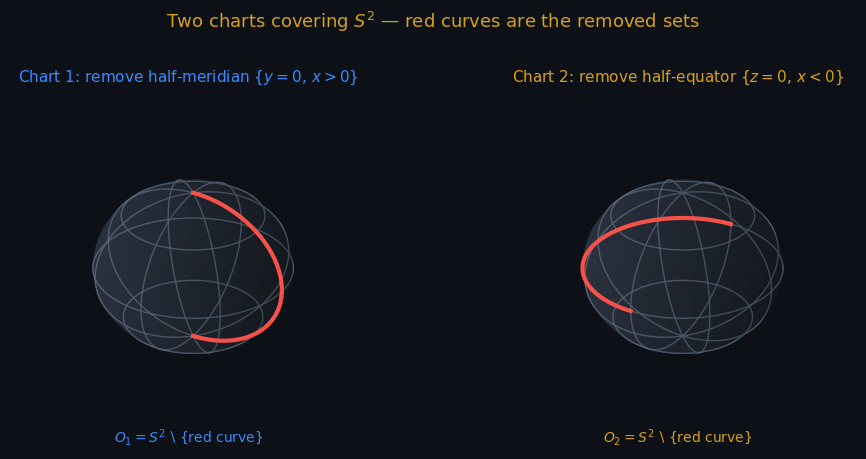

Fig 3 saved.


In [4]:
fig = plt.figure(figsize=(10, 4.5), facecolor=BG)

for col_idx, (title, col) in enumerate([
    (r'Chart 1: remove half-meridian $\{y=0,\,x>0\}$', BLUE),
    (r'Chart 2: remove half-equator $\{z=0,\,x<0\}$',  GOLD)
]):
    ax = fig.add_subplot(1, 2, col_idx+1, projection='3d')
    ax.set_facecolor(BG)
    ax.patch.set_facecolor(BG)

    # Sphere surface
    u = np.linspace(0, 2*np.pi, 60)
    v = np.linspace(0, np.pi, 40)
    xs = np.outer(np.cos(u), np.sin(v))
    ys = np.outer(np.sin(u), np.sin(v))
    zs = np.outer(np.ones_like(u), np.cos(v))
    ax.plot_surface(xs, ys, zs, alpha=0.3, color='#4a5568', zorder=1)

    # Latitude / longitude grid lines
    phi_lines = np.linspace(0, 2*np.pi, 100)
    for lat in [0, np.pi/4, np.pi/2, 3*np.pi/4]:
        ax.plot(np.sin(lat)*np.cos(phi_lines),
                np.sin(lat)*np.sin(phi_lines),
                np.full_like(phi_lines, np.cos(lat)),
                color='#6b7a8d', lw=1.0, alpha=0.9)
    for lon in np.linspace(0, 2*np.pi, 8, endpoint=False):
        v_line = np.linspace(0, np.pi, 50)
        ax.plot(np.sin(v_line)*np.cos(lon),
                np.sin(v_line)*np.sin(lon),
                np.cos(v_line),
                color='#6b7a8d', lw=1.0, alpha=0.9)

    # Removed set — drawn ON the sphere surface (r=1)
    if col_idx == 0:
        # Chart 1: half-meridian y=0, x>0  (phi=0, theta: 0→pi)
        # Points: (sin(theta), 0, cos(theta))  for theta in [0, pi]
        theta_rem = np.linspace(0, np.pi, 100)
        ax.plot(np.sin(theta_rem),          # x = sin(theta) > 0
                np.zeros_like(theta_rem),   # y = 0
                np.cos(theta_rem),          # z = cos(theta)
                color=RED, lw=3, zorder=5)
    else:
        # Chart 2: half-equator z=0, x<0  (theta=pi/2, phi: pi/2→3pi/2)
        # Points: (cos(phi), sin(phi), 0)  for phi in [pi/2, 3pi/2]
        phi_rem = np.linspace(np.pi/2, 3*np.pi/2, 100)
        ax.plot(np.cos(phi_rem),            # x = cos(phi) < 0
                np.sin(phi_rem),            # y = sin(phi)
                np.zeros_like(phi_rem),     # z = 0
                color=RED, lw=3, zorder=5)

    ax.set_axis_off()
    ax.set_title(title, color=col, fontsize=11, pad=8)
    ax.text2D(0.5, 0.02,
              r'$O_{' + str(col_idx+1) + r'}= S^2\setminus\{\mathrm{red\ curve}\}$',
              transform=ax.transAxes, color=col, fontsize=10, ha='center')

fig.suptitle(r'Two charts covering $S^2$ — red curves are the removed sets',
             color=GOLD, fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig('figures/gr_ch2_fig03_sphere_charts.png', dpi=150,
            bbox_inches='tight', facecolor=BG)
plt.show()
print('Fig 3 saved.')

## Fig 4: Tangent Space at a Point

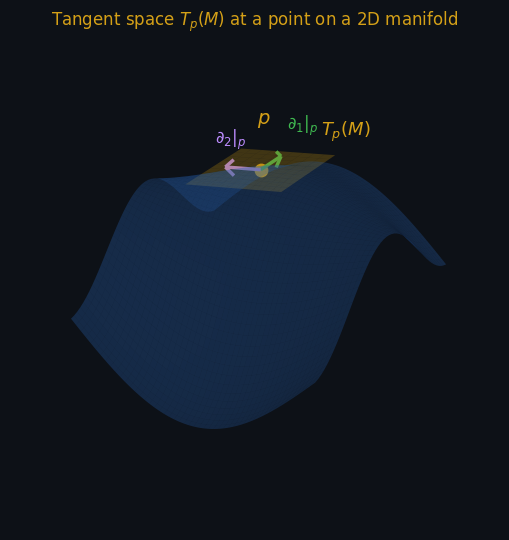

Fig 4 saved.


In [5]:
fig = plt.figure(figsize=(7, 5.5), facecolor=BG)
ax = fig.add_subplot(111, projection='3d')
ax.set_facecolor(BG)
ax.patch.set_facecolor(BG)

# Surface (wavy, like a generic 2D manifold)
u = np.linspace(-1.5, 1.5, 50)
v = np.linspace(-1.5, 1.5, 50)
U, V = np.meshgrid(u, v)
Z = 0.3*np.sin(U)*np.cos(V) + 0.15*np.cos(2*U)
ax.plot_surface(U, V, Z, alpha=0.25, color='#388bfd', zorder=1)

# Point p on the surface
p = np.array([0.5, 0.3])
zp = 0.3*np.sin(p[0])*np.cos(p[1]) + 0.15*np.cos(2*p[0])
ax.scatter([p[0]], [p[1]], [zp], color=GOLD, s=80, zorder=10)
ax.text(p[0]+0.1, p[1]+0.1, zp+0.15, r'$p$', color=GOLD, fontsize=14, fontweight='bold')

# Tangent plane at p
# Normal to surface
dx = 0.3*np.cos(p[0])*np.cos(p[1]) - 0.3*np.sin(2*p[0])
dy = -0.3*np.sin(p[0])*np.sin(p[1])
normal = np.array([-dx, -dy, 1.0])
normal /= np.linalg.norm(normal)

# Span two tangent directions
t1 = np.array([1.0, 0.0, dx])
t1 /= np.linalg.norm(t1)
t2 = np.array([0.0, 1.0, dy])
t2 /= np.linalg.norm(t2)

ss = np.linspace(-0.6, 0.6, 10)
tt = np.linspace(-0.6, 0.6, 10)
SS, TT = np.meshgrid(ss, tt)
Xp = p[0] + SS*t1[0] + TT*t2[0]
Yp = p[1] + SS*t1[1] + TT*t2[1]
Zp = zp  + SS*t1[2] + TT*t2[2]
ax.plot_surface(Xp, Yp, Zp, alpha=0.35, color=GOLD, zorder=5)

# Two basis vectors in tangent plane
scale = 0.45
for vec, col, label in [(t1, GREEN, r'$\partial_1|_p$'), (t2, PURPLE, r'$\partial_2|_p$')]:
    ax.quiver(p[0], p[1], zp,
              vec[0]*scale, vec[1]*scale, vec[2]*scale,
              color=col, lw=2.5, arrow_length_ratio=0.25, zorder=10)
    ax.text(p[0]+vec[0]*scale*1.3, p[1]+vec[1]*scale*1.3, zp+vec[2]*scale*1.3+0.08,
            label, color=col, fontsize=12, fontweight='bold')

# Label the tangent plane
ax.text(p[0]+0.35, p[1]-0.55, zp+0.12, r'$T_p(M)$', color=GOLD, fontsize=13, fontweight='bold')

ax.set_axis_off()
ax.set_title(r'Tangent space $T_p(M)$ at a point on a 2D manifold',
             color=GOLD, fontsize=12, pad=10)
ax.view_init(elev=25, azim=210)

plt.tight_layout()
plt.savefig('figures/gr_ch2_fig04_tangent_space.png', dpi=150, bbox_inches='tight', facecolor=BG)
plt.show()
print('Fig 4 saved.')

## Fig 5: Integral Curves — Flow on S² and ℝ²

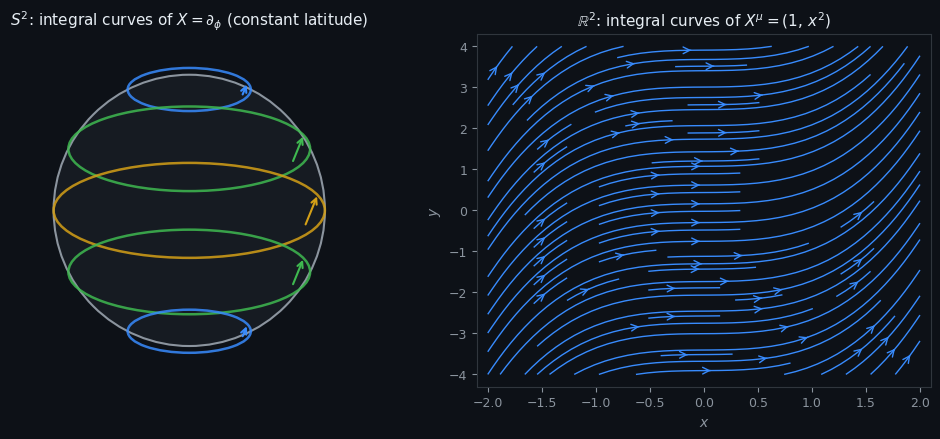

Fig 5 saved.


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), facecolor=BG)

# ---- LEFT: Flow on S^2 (X = d/dphi -> latitude circles) ----
ax1 = axes[0]
ax1.set_facecolor(BG)
ax1.set_aspect('equal')
ax1.axis('off')

sphere = Ellipse((0, 0), 2.0, 2.0, facecolor='#161b22',
                 edgecolor=MUTED, lw=1.5, zorder=1)
ax1.add_patch(sphere)

# Orthographic projection of latitude circles onto the xz-plane:
#   centre: (0, cos(theta))
#   semi-major axis (horizontal): sin(theta)
#   semi-minor axis (vertical):   ASPECT * sin(theta)   <- constant ratio
ASPECT = 0.35

colors_lat = [BLUE, GREEN, GOLD, GREEN, BLUE]
for lat_frac, col in zip([0.15, 0.35, 0.5, 0.65, 0.85], colors_lat):
    lat   = np.pi * lat_frac
    r_lat = np.sin(lat)          # radius of latitude circle
    z_lat = np.cos(lat)          # height on sphere

    ax1.add_patch(Ellipse(
        (0, z_lat),
        width  = 2 * r_lat,          # full width  = 2 sin(theta)
        height = 2 * ASPECT * r_lat, # full height = 2 * ASPECT * sin(theta)
        facecolor='none', edgecolor=col, lw=1.8, alpha=0.85, zorder=3
    ))

    # Arrow at the rightmost point of the ellipse, pointing upward (phi increases CCW)
    ax1.annotate('',
        xy     = (r_lat * 0.95,  z_lat + ASPECT * r_lat * 0.35),
        xytext = (r_lat * 0.85,  z_lat - ASPECT * r_lat * 0.35),
        arrowprops=dict(arrowstyle='->', color=col, lw=1.5)
    )

ax1.set_xlim(-1.3, 1.3)
ax1.set_ylim(-1.3, 1.3)
ax1.set_title(r'$S^2$: integral curves of $X=\partial_\phi$ (constant latitude)',
              color=TEXT, fontsize=11, pad=6)

# ---- RIGHT: Flow in R^2 with X^mu = (1, x^2) ----
ax2 = axes[1]
ax2.set_facecolor(BG)

x_range = np.linspace(-2, 2, 15)
y_range = np.linspace(-4, 4, 20)
X2, Y2 = np.meshgrid(x_range, y_range)
U2 = np.ones_like(X2)
V2 = X2**2
ax2.streamplot(x_range, y_range, U2, V2,
               color=BLUE, linewidth=1.0, density=1.2,
               arrowsize=1.2, arrowstyle='->')

ax2.set_xlim(-2.1, 2.1)
ax2.set_ylim(-4.3, 4.3)
ax2.set_xlabel(r'$x$', color=MUTED)
ax2.set_ylabel(r'$y$', color=MUTED)
ax2.tick_params(colors=MUTED, labelsize=9)
for spine in ax2.spines.values():
    spine.set_edgecolor('#30363d')
ax2.set_title(r'$\mathbb{R}^2$: integral curves of $X^\mu=(1,\,x^2)$',
              color=TEXT, fontsize=11, pad=6)

plt.tight_layout()
plt.savefig('figures/gr_ch2_fig05_integral_curves.png', dpi=150,
            bbox_inches='tight', facecolor=BG)
plt.show()
print('Fig 5 saved.')

## Download figures ZIP

In [7]:
import shutil
shutil.make_archive('gr_ch02_figures', 'zip', '.', 'figures')
print('ZIP created: gr_ch02_figures.zip')

try:
    from google.colab import files
    files.download('gr_ch02_figures.zip')
except ImportError:
    print('Not in Colab — find gr_ch02_figures.zip in the current directory.')

ZIP created: gr_ch02_figures.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>